# Baseball Pitch Type Classification
Predict the pitch type (fastball, slider, curveball, changeup...) from how the ball was thrown: speed, spin and movement.

**Data:** MLB Statcast data pulled live with the pybaseball library (a few days of the 2023 season). Needs internet in Colab and takes 1 to 3 minutes. If the pull fails, a small synthetic sample is made.

**Important:** train and test are split by pitcher, so the model is tested on pitchers it has never seen.

In [1]:
!pip install -q pybaseball scikit-learn pandas matplotlib

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

try:
    from pybaseball import statcast
    df = statcast(start_dt="2023-06-01", end_dt="2023-06-05")
    print("real data loaded:", df.shape)
except Exception as e:
    print("could not pull statcast data, making synthetic data instead:", e)
    types = {"FF": (94, 2300, -6, 16), "SL": (86, 2450, 2, 2), "CU": (79, 2650, 8, -8),
             "CH": (85, 1750, -14, 6), "SI": (93, 2150, -14, 9), "FC": (89, 2400, 0, 8)}
    rows = []
    for t, (spd, spin, hx, hz) in types.items():
        for i in range(1500):
            rows.append({"pitch_type": t, "release_speed": np.random.normal(spd, 2), "release_spin_rate": np.random.normal(spin, 150),
                         "pfx_x": np.random.normal(hx, 3) / 12 * 1, "pfx_z": np.random.normal(hz, 3) / 12 * 1,
                         "release_pos_x": np.random.normal(-1, 1), "release_pos_z": np.random.normal(5.8, 0.4),
                         "release_extension": np.random.normal(6.4, 0.4), "spin_axis": np.random.normal(200, 40),
                         "p_throws": np.random.choice(["R", "L"]), "pitcher": np.random.randint(1, 80)})
    df = pd.DataFrame(rows)

df[["pitch_type", "release_speed", "release_spin_rate", "pfx_x", "pfx_z"]].head()

This is a large query, it may take a moment to complete


  0%|          | 0/5 [00:00<?, ?it/s]/usr/local/lib/python3.13/dist-packages/pybaseball/datahelpers/postprocessing.py:59: FutureWarning: errors='ignore' is deprecated and will raise in a future version. Use to_datetime without passing `errors` and catch exceptions explicitly instead
  data_copy[column] = data_copy[column].apply(pd.to_datetime, errors='ignore', format=date_format)
/usr/local/lib/python3.13/dist-packages/pybaseball/datahelpers/postprocessing.py:59: FutureWarning: errors='ignore' is deprecated and will raise in a future version. Use to_datetime without passing `errors` and catch exceptions explicitly instead
  data_copy[column] = data_copy[column].apply(pd.to_datetime, errors='ignore', format=date_format)
/usr/local/lib/python3.13/dist-packages/pybaseball/datahelpers/postprocessing.py:59: FutureWarning: errors='ignore' is deprecated and will raise in a future version. Use to_datetime without passing `errors` and catch exceptions explicitly instead
  data_copy[column] = da

real data loaded: (17528, 119)


,pitch_type,release_speed,release_spin_rate,pfx_x,pfx_z
1685,CH,91.3,1333,-1.51,0.44
1704,CH,89.6,1228,-1.27,0.1
1765,CH,89.2,2814,-1.52,0.02
1854,CH,91.0,2418,-1.03,0.56
1903,FF,95.7,2721,-0.68,1.53


In [3]:
use_cols = ["pitch_type", "release_speed", "release_spin_rate", "pfx_x", "pfx_z",
            "release_pos_x", "release_pos_z", "release_extension", "spin_axis", "p_throws", "pitcher"]
data = df[use_cols].dropna().copy()
data["throws_right"] = (data["p_throws"] == "R").astype(int)

counts = data["pitch_type"].value_counts()
print(counts)
keep = counts[counts >= 300].index
data = data[data["pitch_type"].isin(keep)]
print("kept pitch types:", list(keep))
print("rows:", len(data), " pitchers:", data["pitcher"].nunique())

pitch_type
FF    5681
SL    2837
SI    2663
CH    1842
FC    1311
CU    1214
ST    1049
FS     372
KC     331
SV      67
FA      23
FO      18
CS       3
SC       1
Name: count, dtype: int64
kept pitch types: ['FF', 'SL', 'SI', 'CH', 'FC', 'CU', 'ST', 'FS', 'KC']
rows: 17300  pitchers: 357


In [4]:
data.groupby("pitch_type")[["release_speed", "release_spin_rate", "pfx_x", "pfx_z"]].mean().round(2)

,release_speed,release_spin_rate,pfx_x,pfx_z
pitch_type,,,,
CH,85.6,1826.84,-0.59,0.51
CU,78.81,2567.64,0.28,-0.82
FC,89.19,2414.48,0.15,0.67
FF,94.53,2297.87,-0.34,1.33
FS,87.32,1432.12,-0.91,0.34
KC,81.58,2488.2,0.5,-0.77
SI,93.28,2148.5,-0.75,0.62
SL,85.68,2437.69,0.18,0.11
ST,81.41,2521.33,0.62,0.09


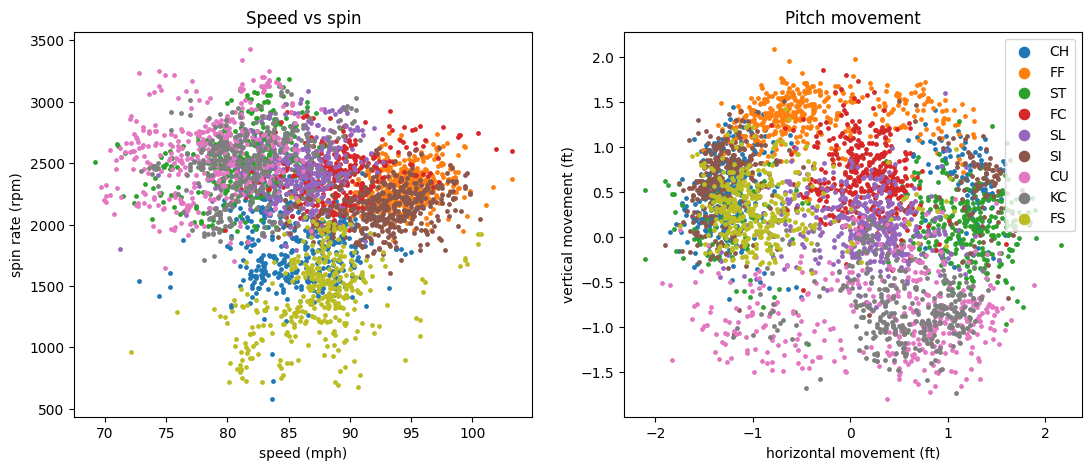

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
for t in data["pitch_type"].unique():
    sub = data[data["pitch_type"] == t].sample(min(400, (data["pitch_type"] == t).sum()), random_state=1)
    ax[0].scatter(sub["release_speed"], sub["release_spin_rate"], s=6, label=t)
    ax[1].scatter(sub["pfx_x"], sub["pfx_z"], s=6, label=t)
ax[0].set_xlabel("speed (mph)")
ax[0].set_ylabel("spin rate (rpm)")
ax[0].set_title("Speed vs spin")
ax[1].set_xlabel("horizontal movement (ft)")
ax[1].set_ylabel("vertical movement (ft)")
ax[1].set_title("Pitch movement")
ax[1].legend(markerscale=3)
plt.show()

In [6]:
from sklearn.model_selection import GroupShuffleSplit
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

features = ["release_speed", "release_spin_rate", "pfx_x", "pfx_z", "release_pos_x", "release_pos_z",
            "release_extension", "spin_axis", "throws_right"]
X = data[features]
y = data["pitch_type"]

splitter = GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=42)
train_idx, test_idx = next(splitter.split(X, y, groups=data["pitcher"]))
X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
print("train rows:", len(X_train), "test rows:", len(X_test))
print("pitchers in both sets:", len(set(data.iloc[train_idx]["pitcher"]) & set(data.iloc[test_idx]["pitcher"])))

most_common = y_train.mode()[0]
print("Baseline accuracy (always", most_common + "):", round(accuracy_score(y_test, [most_common] * len(y_test)), 4))

train rows: 12936 test rows: 4364
pitchers in both sets: 0
Baseline accuracy (always FF): 0.2979


In [7]:
lr = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000))
lr.fit(X_train, y_train)
lr_pred = lr.predict(X_test)
print("Logistic Regression  accuracy:", round(accuracy_score(y_test, lr_pred), 4), " macro F1:", round(f1_score(y_test, lr_pred, average="macro"), 4))

rf = RandomForestClassifier(n_estimators=150, max_depth=14, n_jobs=-1, random_state=42)
rf.fit(X_train, y_train)
rf_pred = rf.predict(X_test)
print("Random Forest        accuracy:", round(accuracy_score(y_test, rf_pred), 4), " macro F1:", round(f1_score(y_test, rf_pred, average="macro"), 4))

gb = HistGradientBoostingClassifier(max_iter=200, learning_rate=0.1, random_state=42)
gb.fit(X_train, y_train)
gb_pred = gb.predict(X_test)
print("Gradient Boosting    accuracy:", round(accuracy_score(y_test, gb_pred), 4), " macro F1:", round(f1_score(y_test, gb_pred, average="macro"), 4))

Logistic Regression  accuracy: 0.7511  macro F1: 0.6041
Random Forest        accuracy: 0.7908  macro F1: 0.6435
Gradient Boosting    accuracy: 0.7713  macro F1: 0.6055


              precision    recall  f1-score   support

          CH      0.703     0.744     0.723       442
          CU      0.743     0.833     0.785       323
          FC      0.607     0.316     0.416       395
          FF      0.890     0.955     0.921      1300
          FS      0.467     0.257     0.331       109
          KC      0.250     0.038     0.066        79
          SI      0.855     0.843     0.849       804
          SL      0.671     0.770     0.717       716
          ST      0.575     0.724     0.641       196

    accuracy                          0.771      4364
   macro avg      0.640     0.609     0.606      4364
weighted avg      0.756     0.771     0.756      4364

         pred CH  pred CU  pred FC  pred FF  pred FS  pred KC  pred SI  \
real CH      329        0        0        0       32        0       76   
real CU        0      269        0        0        0        7        0   
real FC        0        0      125       87        0        0        0   

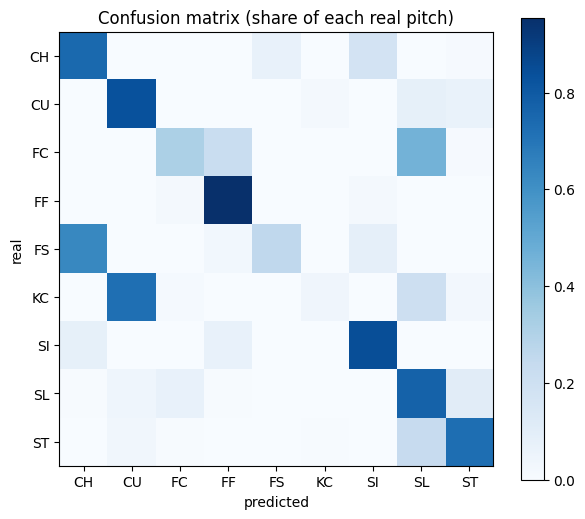

In [8]:
print(classification_report(y_test, gb_pred, digits=3))

labels = sorted(y.unique())
cm = confusion_matrix(y_test, gb_pred, labels=labels)
cm_df = pd.DataFrame(cm, index=["real " + l for l in labels], columns=["pred " + l for l in labels])
print(cm_df)

plt.figure(figsize=(7, 6))
plt.imshow(cm / cm.sum(axis=1, keepdims=True), cmap="Blues")
plt.xticks(range(len(labels)), labels)
plt.yticks(range(len(labels)), labels)
plt.xlabel("predicted")
plt.ylabel("real")
plt.title("Confusion matrix (share of each real pitch)")
plt.colorbar()
plt.show()

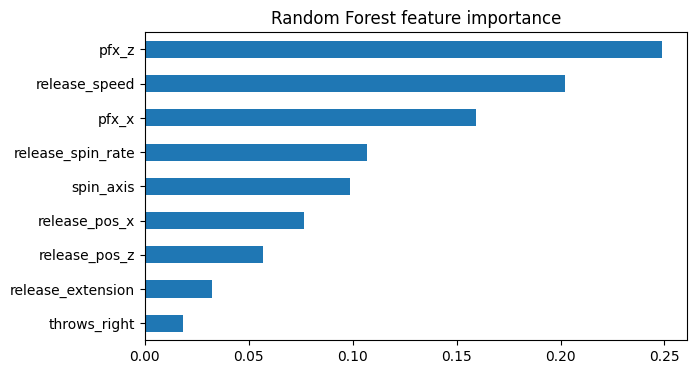

throws_right         0.018
release_extension    0.033
release_pos_z        0.057
release_pos_x        0.077
spin_axis            0.099
release_spin_rate    0.107
pfx_x                0.160
release_speed        0.202
pfx_z                0.249
dtype: float64

most common mistakes:
real  predicted
FC    SL           180
      FF            87
CH    SI            76
SL    ST            75
FS    CH            69
SI    CH            64
      FF            59
KC    CU            57
dtype: int64


In [9]:
imp = pd.Series(rf.feature_importances_, index=features).sort_values()
imp.plot(kind="barh", figsize=(7, 4), title="Random Forest feature importance")
plt.show()
print(imp.round(3))

wrong = pd.DataFrame({"real": y_test.values, "predicted": gb_pred})
wrong = wrong[wrong["real"] != wrong["predicted"]]
print()
print("most common mistakes:")
print(wrong.groupby(["real", "predicted"]).size().sort_values(ascending=False).head(8))

In [ ]:

# ============================================================
# UNIVERSAL COLAB PROJECT AUTO-SAVE
# Structure: Parent Folder / Notebook Name / All Project Files
# ============================================================

import os
import json
import shutil
from pathlib import Path
from google.colab import auth, _message
from googleapiclient.discovery import build
from googleapiclient.http import MediaFileUpload
from google.auth import default

# 1. DESTINATION GOOGLE DRIVE FOLDER
PARENT_FOLDER_ID = "1RJ_KbIui8TyupB2kr3c-N93lt2OE0nAk"

# 2. AUTHENTICATE
auth.authenticate_user()
credentials, _ = default()
drive = build("drive", "v3", credentials=credentials)

# 3. DETECT CURRENT NOTEBOOK
notebook_data = _message.blocking_request("get_ipynb")

if "ipynb" in notebook_data:
    notebook_data = notebook_data["ipynb"]

project_name = (
    notebook_data.get("metadata", {})
    .get("colab", {})
    .get("name", "")
)

if not project_name:
    project_name = input("Enter your Colab notebook name (e.g. RAG): ").strip()

project_name = Path(project_name).stem

if not project_name:
    raise ValueError("Project name is missing.")

print("Project detected:", project_name)

# 4. FIND OR CREATE PROJECT FOLDER
query = (
    f"'{PARENT_FOLDER_ID}' in parents "
    f"and name = '{project_name}' "
    "and mimeType = 'application/vnd.google-apps.folder' "
    "and trashed = false"
)

results = drive.files().list(
    q=query,
    fields="files(id,name)",
    supportsAllDrives=True,
    includeItemsFromAllDrives=True
).execute()

if results.get("files"):
    PROJECT_FOLDER_ID = results["files"][0]["id"]
else:
    folder = drive.files().create(
        body={
            "name": project_name,
            "mimeType": "application/vnd.google-apps.folder",
            "parents": [PARENT_FOLDER_ID]
        },
        fields="id"
    ).execute()

    PROJECT_FOLDER_ID = folder["id"]

# 5. UPLOAD FILES WITHOUT ZIP
SKIP_DIRS = {
    "drive", "sample_data", ".config",
    ".cache", "__pycache__"
}

uploaded = 0
failed = []

def find_existing_file(name, parent_id):
    q = (
        f"'{parent_id}' in parents "
        f"and name = '{name}' "
        "and trashed = false"
    )
    found = drive.files().list(
        q=q,
        fields="files(id)",
        supportsAllDrives=True,
        includeItemsFromAllDrives=True
    ).execute()
    return found.get("files", [])

def upload_file(local_path, parent_id):
    global uploaded

    filename = os.path.basename(local_path)

    metadata = {
        "name": filename,
        "parents": [parent_id]
    }

    media = MediaFileUpload(
        local_path,
        resumable=True
    )

    existing = find_existing_file(filename, parent_id)

    if existing:
        drive.files().update(
            fileId=existing[0]["id"],
            media_body=media,
            supportsAllDrives=True
        ).execute()
    else:
        drive.files().create(
            body=metadata,
            media_body=media,
            fields="id",
            supportsAllDrives=True
        ).execute()

    uploaded += 1
    print("Saved:", filename)

def upload_directory(local_dir, drive_parent_id):
    for item in os.scandir(local_dir):

        if item.is_dir(follow_symlinks=False):

            if item.name in SKIP_DIRS:
                continue

            existing = find_existing_file(
                item.name, drive_parent_id
            )

            if existing:
                subfolder_id = existing[0]["id"]
            else:
                result = drive.files().create(
                    body={
                        "name": item.name,
                        "mimeType": "application/vnd.google-apps.folder",
                        "parents": [drive_parent_id]
                    },
                    fields="id",
                    supportsAllDrives=True
                ).execute()
                subfolder_id = result["id"]

            upload_directory(item.path, subfolder_id)

        elif item.is_file(follow_symlinks=False):
            try:
                upload_file(item.path, drive_parent_id)
            except Exception as error:
                failed.append((item.name, str(error)))
                print("Upload failed:", item.name, error)

# 6. SAVE EXECUTED NOTEBOOK
notebook_path = f"/content/{project_name}.ipynb"

with open(notebook_path, "w", encoding="utf-8") as f:
    json.dump(notebook_data, f, ensure_ascii=False, indent=2)

# 7. UPLOAD PROJECT FILES
upload_directory("/content", PROJECT_FOLDER_ID)

# 8. FINAL REPORT
print("\n======================================")
print("PROJECT BACKUP COMPLETED")
print("======================================")
print("Project:", project_name)
print("Uploaded files:", uploaded)
print("Failed files:", len(failed))
print(
    "Folder:",
    f"https://drive.google.com/drive/folders/{PROJECT_FOLDER_ID}"
)

if failed:
    print("\nFailed uploads:")
    for name, error in failed:
        print(name, error)